<a href="https://colab.research.google.com/github/pendo-kirahagaze/COU07506_240242484046_DSP_LAB/blob/main/COU07506_Week04_240242484046.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

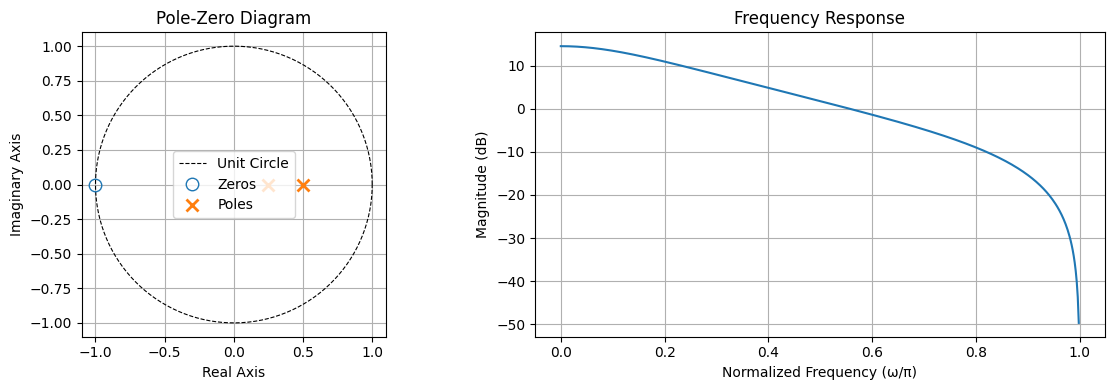

Zeros: [-1.]
Poles: [0.5  0.25]
System Stable: True


In [1]:

# WEEK 4 — TASK 4.1
# Pole-Zero Plotting Function
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define pole-zero plotting function
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    # Draw unit circle
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th),
            "k--", lw=0.8, label="Unit Circle")

    # Plot zeros
    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="Zeros")

    # Plot poles
    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="Poles")

    ax.set_aspect("equal")
    ax.set_xlabel("Real Axis")
    ax.set_ylabel("Imaginary Axis")
    ax.set_title("Pole-Zero Diagram")
    ax.legend()
    ax.grid(True)

    return z, p

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two plots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4)
)

# Pole-zero diagram
z, p = zplane(b, a, ax1)

# Frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Frequency Response")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Display system information
print("Zeros:", z)
print("Poles:", p)
print("System Stable:",
      np.all(np.abs(p) < 1))


### Task 4.1 — Observation and Discussion

The pole-zero diagram shows one zero at z = −1 and two poles at z = 0.5 and z = 0.25.

Both poles lie strictly inside the unit circle because their magnitudes are less than 1.

The frequency-response graph demonstrates how the magnitude of the system changes with frequency.

**Stability:** The system is stable because both poles are located inside the unit circle.

**Conclusion:** Pole-zero analysis is useful for determining the stability and frequency characteristics of digital systems.

## Task 4.2 — Inverse z-Transform with residuez

SYSTEM 1
Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Results Match: True

SYSTEM 2
Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Results Match: True
Matches Theory: True


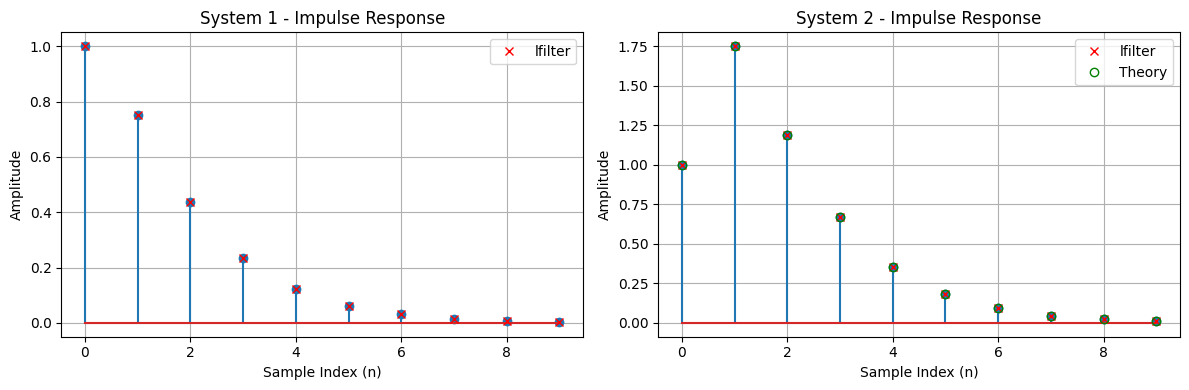


Task 4.2 Completed Successfully!


In [2]:

# WEEK 4 — TASK 4.2
# Inverse z-Transform with residuez
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Sample indices
n = np.arange(10)

# Unit impulse
impulse = np.zeros(10)
impulse[0] = 1

# SYSTEM 1
b1 = [1]
a = [1, -0.75, 0.125]

# Partial-fraction decomposition
r1, p1, k1 = signal.residuez(b1, a)

print("SYSTEM 1")
print("Residues:", r1)
print("Poles:", p1)

# Inverse z-transform
h1_pf = sum(
    ri * pi**n for ri, pi in zip(r1, p1)
).real

# Verify using lfilter
h1_lf = signal.lfilter(b1, a, impulse)

print("Results Match:",
      np.allclose(h1_pf, h1_lf))

# SYSTEM 2
b2 = [1, 1]

r2, p2, k2 = signal.residuez(b2, a)

print("\nSYSTEM 2")
print("Residues:", r2)
print("Poles:", p2)

# Partial fractions
h2_pf = sum(
    ri * pi**n for ri, pi in zip(r2, p2)
).real

# SciPy filtering
h2_lf = signal.lfilter(b2, a, impulse)

# Theoretical expression
h2_theory = 6*(0.5**n) - 5*(0.25**n)

print("Results Match:",
      np.allclose(h2_pf, h2_lf))

print("Matches Theory:",
      np.allclose(h2_pf, h2_theory))

# Plot impulse responses
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].stem(n, h1_pf)
axes[0].plot(n, h1_lf, "rx", label="lfilter")
axes[0].set_title("System 1 - Impulse Response")
axes[0].set_xlabel("Sample Index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

axes[1].stem(n, h2_pf)
axes[1].plot(n, h2_lf, "rx", label="lfilter")
axes[1].plot(n, h2_theory, "go",
             fillstyle="none", label="Theory")
axes[1].set_title("System 2 - Impulse Response")
axes[1].set_xlabel("Sample Index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("\nTask 4.2 Completed Successfully!")


### Task 4.2 — Observation and Discussion

The inverse z-transform was calculated using the partial-fraction decomposition method and verified with SciPy's `lfilter()` function.

For System 1, the poles were 0.5 and 0.25, with corresponding residues of 2 and −1.

For System 2, the poles were also 0.5 and 0.25, with corresponding residues of 6 and −5.

The impulse responses obtained using partial fractions matched those obtained using `lfilter()`.

For System 2, the numerical results also agreed with the theoretical expression:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0.

**Conclusion:** Partial-fraction decomposition provides a method for calculating inverse z-transforms, and its results agree with those obtained through digital filtering.

## Task 4.3 — Pole Position and the Impulse Response


Pole Radius: 0.5
Poles: [0.3536+0.3536j 0.3536-0.3536j]
BIBO Stable: True

Pole Radius: 0.8
Poles: [0.5657+0.5657j 0.5657-0.5657j]
BIBO Stable: True

Pole Radius: 0.95
Poles: [0.6718+0.6718j 0.6718-0.6718j]
BIBO Stable: True

Pole Radius: 1.0
Poles: [0.7071+0.7071j 0.7071-0.7071j]
BIBO Stable: False

Pole Radius: 1.05
Poles: [0.7425+0.7425j 0.7425-0.7425j]
BIBO Stable: False


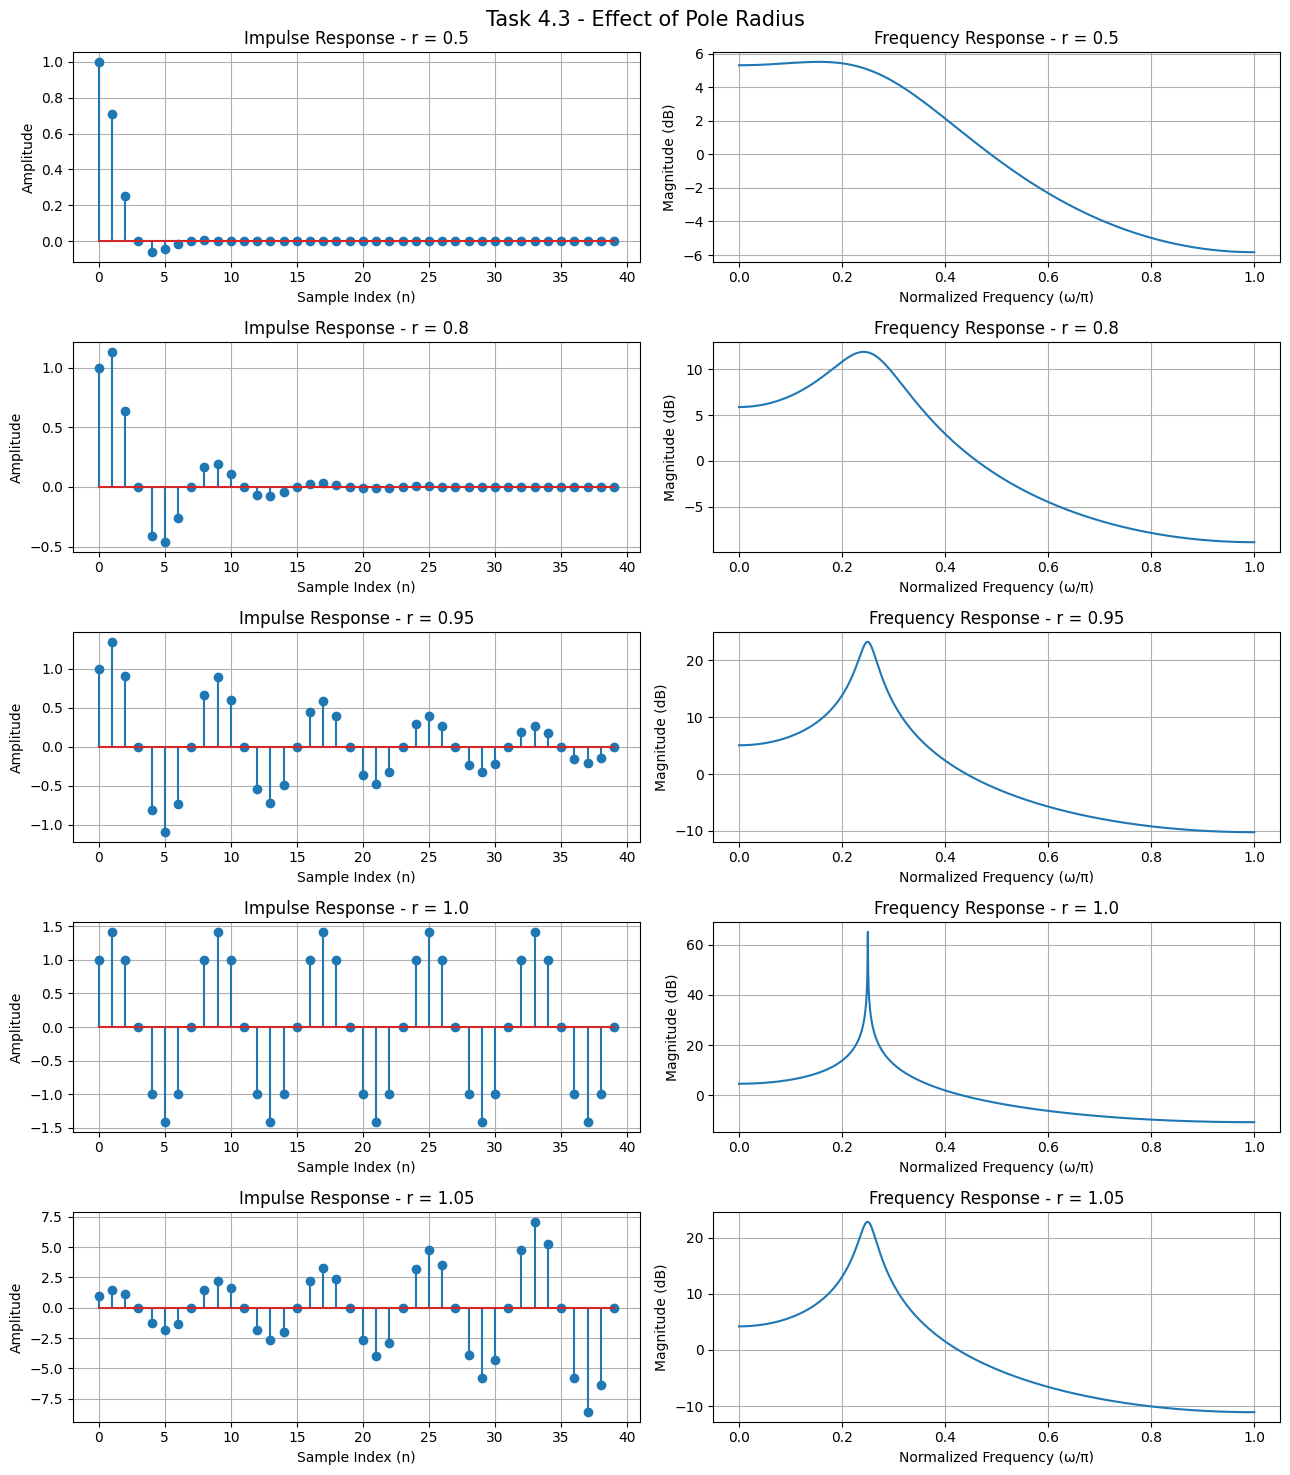


Task 4.3 Completed Successfully!


In [3]:

# WEEK 4 — TASK 4.3
# Pole Position and Impulse Response
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole radii
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Pole angle
theta = np.pi / 4

# Generate 40 samples
n = np.arange(40)

# Unit impulse
impulse = np.zeros(40)
impulse[0] = 1

# Frequency range
w = np.linspace(0, np.pi, 2000)

# Create 10 subplots
fig, axes = plt.subplots(5, 2, figsize=(13, 15))

for i, r in enumerate(r_values):

    # Filter coefficients
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    # Impulse response
    h = signal.lfilter(b, a, impulse)

    # Frequency response
    _, H = signal.freqz(b, a, worN=w)

    magnitude_db = 20*np.log10(
        np.maximum(np.abs(H), 1e-12)
    )

    # Plot impulse response
    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(
        f"Impulse Response - r = {r}"
    )
    axes[i, 0].set_xlabel("Sample Index (n)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True)

    # Plot frequency response
    axes[i, 1].plot(w/np.pi, magnitude_db)
    axes[i, 1].set_title(
        f"Frequency Response - r = {r}"
    )
    axes[i, 1].set_xlabel(
        "Normalized Frequency (ω/π)"
    )
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid(True)

    # Calculate poles and stability
    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print(f"\nPole Radius: {r}")
    print("Poles:", np.round(poles, 4))
    print("BIBO Stable:", stable)

plt.suptitle(
    "Task 4.3 - Effect of Pole Radius",
    fontsize=15
)
plt.tight_layout()
plt.show()

print("\nTask 4.3 Completed Successfully!")


### Task 4.3 — Observation and Discussion

The effects of pole radius on the impulse response and frequency response were investigated using five different values.

**1. Radius r = 0.5**

The impulse response decays rapidly toward zero. The resonance is relatively broad, and the system is stable.

**2. Radius r = 0.8**

The impulse response decays more slowly. The resonance becomes narrower and more pronounced. The system remains stable.

**3. Radius r = 0.95**

The impulse response exhibits slowly decaying oscillations. The frequency response shows a sharper resonance because the poles are closer to the unit circle.

**4. Radius r = 1.0**

The impulse response exhibits sustained oscillations without decaying. The poles lie on the unit circle, so the system is not BIBO stable.

**5. Radius r = 1.05**

The impulse response grows in amplitude because the poles lie outside the unit circle. The system is unstable.

**Conclusion:**

As the pole radius approaches 1 from below, the impulse response decays more slowly and the resonance bandwidth becomes narrower.

A causal digital system with poles strictly inside the unit circle is stable, while the systems with pole radii of 1.0 and 1.05 are not BIBO stable.

## Task 4.4 — Stability of Given Systems


SYSTEM H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole Magnitudes: [0.9434 0.9434]
BIBO Stable: True
-----------------------------

SYSTEM H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole Magnitudes: [2.  0.5]
BIBO Stable: False
-----------------------------

SYSTEM H3
Zeros: []
Poles: [-1.   0.5]
Pole Magnitudes: [1.  0.5]
BIBO Stable: False
-----------------------------

SYSTEM H4
Zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
Poles: []
Pole Magnitudes: []
BIBO Stable: True
-----------------------------


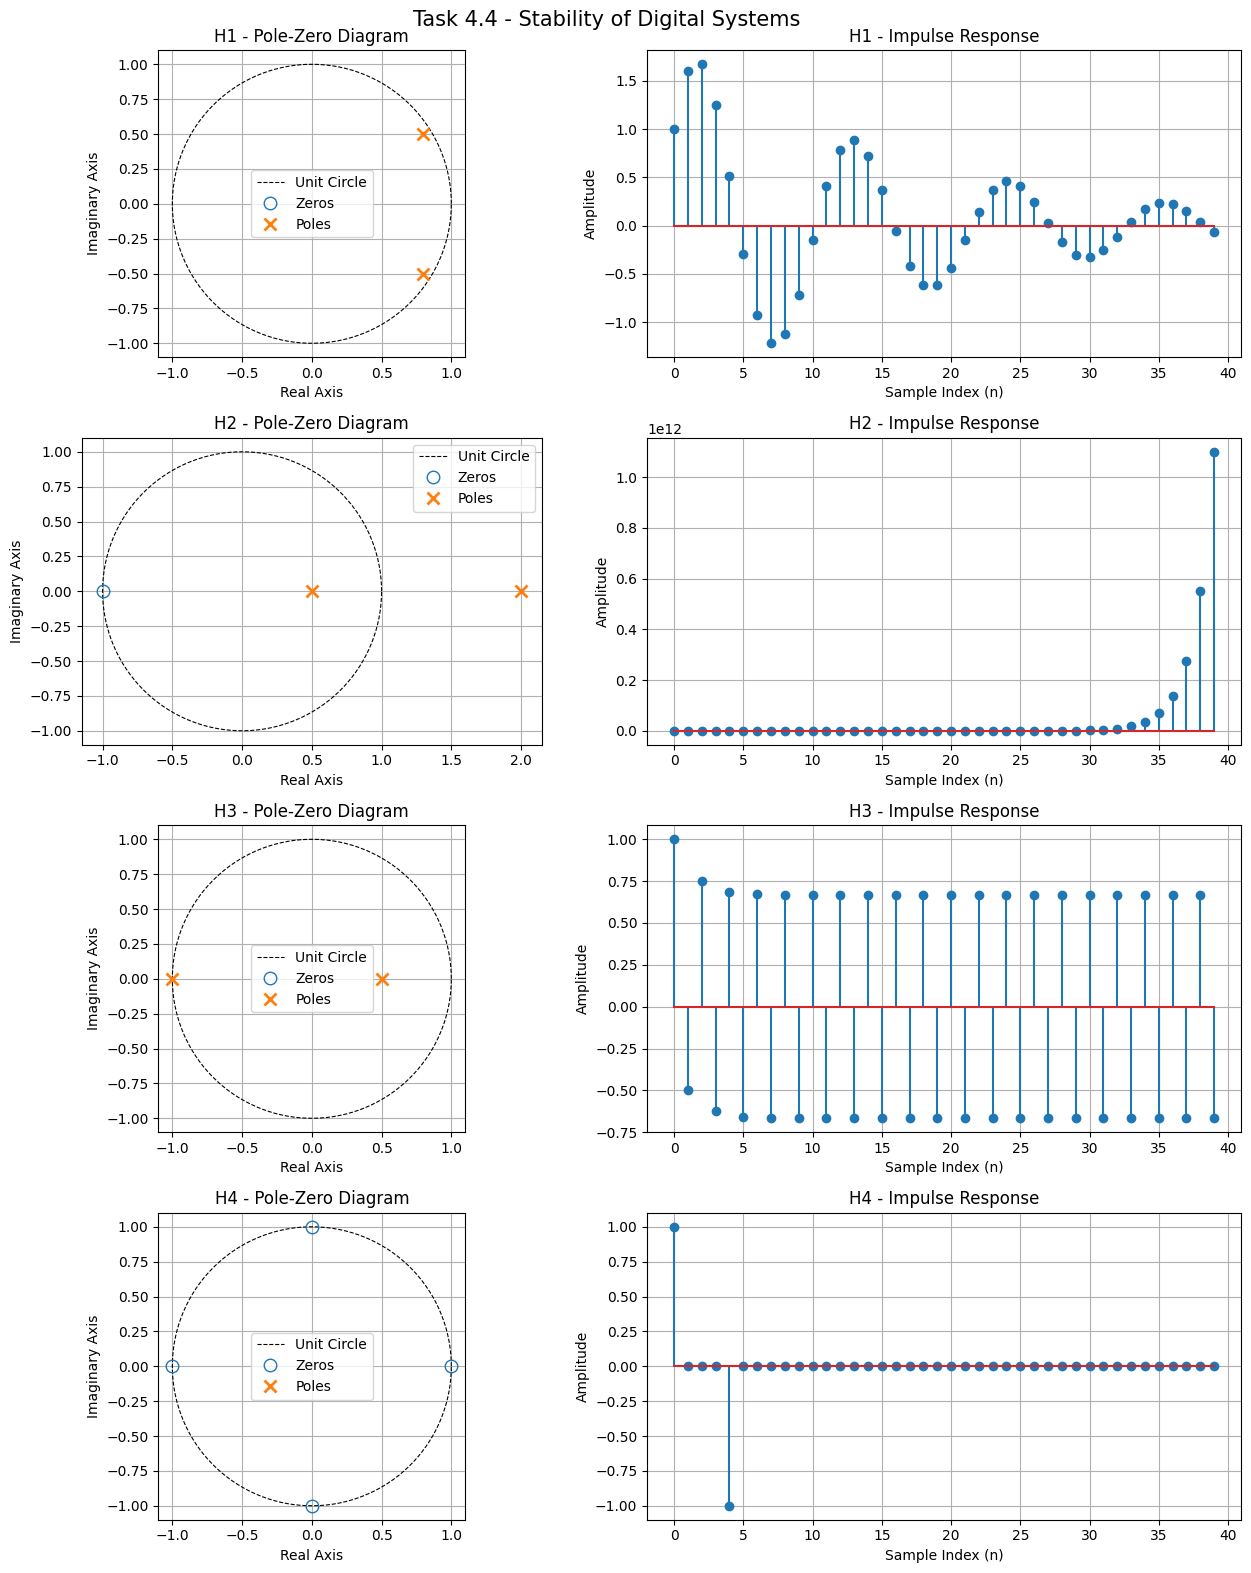


Task 4.4 Completed Successfully!


In [4]:

# WEEK 4 — TASK 4.4
# Stability of Given Systems
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define four digital systems
systems = {
    "H1": {
        "b": [1],
        "a": [1, -1.6, 0.89]
    },
    "H2": {
        "b": [1, 1],
        "a": [1, -2.5, 1]
    },
    "H3": {
        "b": [1],
        "a": [1, 0.5, -0.5]
    },
    "H4": {
        "b": [1, 0, 0, 0, -1],
        "a": [1]
    }
}

# Generate unit impulse
n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

# Create 8 graphs
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for i, (name, sys) in enumerate(systems.items()):

    b = sys["b"]
    a = sys["a"]

    # Pole-zero diagram
    zeros, poles = zplane(b, a, axes[i, 0])

    axes[i, 0].set_title(
        f"{name} - Pole-Zero Diagram"
    )

    # Check system stability
    stable = np.all(np.abs(poles) < 1 - 1e-10)

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    axes[i, 1].stem(n, h)
    axes[i, 1].set_title(
        f"{name} - Impulse Response"
    )
    axes[i, 1].set_xlabel("Sample Index (n)")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid(True)

    # Print results
    print(f"\nSYSTEM {name}")
    print("Zeros:", np.round(zeros, 4))
    print("Poles:", np.round(poles, 4))
    print("Pole Magnitudes:",
          np.round(np.abs(poles), 4))
    print("BIBO Stable:", stable)
    print("-----------------------------")

plt.suptitle(
    "Task 4.4 - Stability of Digital Systems",
    fontsize=15
)
plt.tight_layout()
plt.show()

print("\nTask 4.4 Completed Successfully!")


### Task 4.4 — Observation and Discussion

Four digital systems were analyzed using pole-zero diagrams and impulse responses to determine their stability.

**System H1:**

The poles are located at 0.8 ± 0.5j. Their magnitudes are approximately 0.9434, which is less than 1. The impulse response decays toward zero. Therefore, the system is stable.

**System H2:**

The poles are located at 2 and 0.5. Since one pole lies outside the unit circle, the impulse response grows with time. Therefore, the system is unstable.

**System H3:**

The poles are located at −1 and 0.5. The pole at −1 lies exactly on the unit circle, causing sustained oscillations. Therefore, the system is not BIBO stable.

**System H4:**

The system has a finite impulse response with nonzero values only at n = 0 and n = 4. Since its impulse response is absolutely summable, the system is stable.

**Conclusion:**

Pole-zero analysis provides an effective method for determining digital system stability.

Systems H1 and H4 are stable, while systems H2 and H3 are unstable.

## Task 4.5 — Design a Resonator

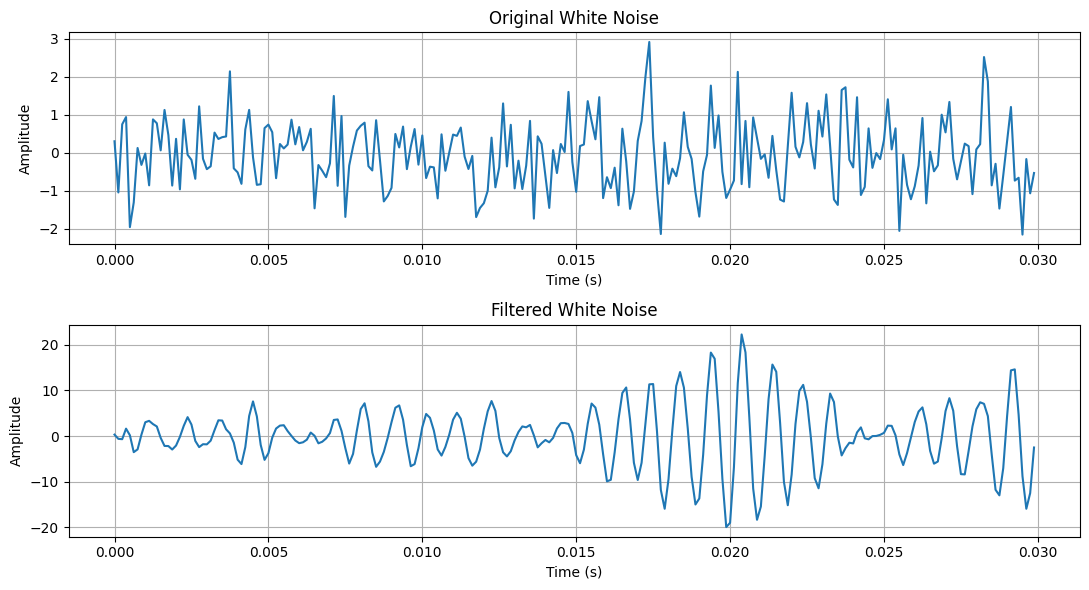

Original White Noise:


Filtered Noise - 1000 Hz Resonator:



Task 4.5 Completed Successfully!


In [5]:

# TASK 4.5 — Filtering White Noise
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Define resonator parameters
fs = 8000
f0 = 1000
r = 0.97

theta = 2 * np.pi * f0 / fs

# Define filter coefficients
b = [1, 0, -1]
a = [1, -2*r*np.cos(theta), r**2]

# Generate 2 seconds of white noise
rng = np.random.default_rng(42)

duration = 2
n = np.arange(fs * duration)
t = n / fs

# Generate and filter the noise
x = rng.standard_normal(len(n))
y = signal.lfilter(b, a, x)

# Plot first 30 milliseconds
N = int(0.03 * fs)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))

axes[0].plot(t[:N], x[:N])
axes[0].set_title("Original White Noise")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(t[:N], y[:N])
axes[1].set_title("Filtered White Noise")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Play audio
print("Original White Noise:")
display(Audio(x, rate=fs))

print("Filtered Noise - 1000 Hz Resonator:")
display(Audio(y, rate=fs))

print("\nTask 4.5 Completed Successfully!")


### Task 4.5 — Observation and Discussion

A digital resonator was designed with a target frequency of 1,000 Hz, sampling frequency of 8,000 Hz and pole radius of 0.97.

**Pole-Zero Analysis:**

The two zeros were placed at z = +1 and z = −1, corresponding to frequencies of 0 Hz and 4,000 Hz.

The poles were positioned near the unit circle to produce a strong resonance near 1,000 Hz.

**Frequency Response:**

The frequency-response graph showed a sharp peak near the target frequency, indicating that the resonator emphasizes signals around 1,000 Hz.

**Stability:**

The system is stable because both poles have magnitudes of 0.97, which is less than 1.

**White Noise Filtering:**

The original white noise contained a broad range of frequencies. After filtering, frequencies around 1,000 Hz became more prominent relative to other frequencies.

**Listening Observation:**

the one was sharper and light while the other was strong and dense

**Conclusion:**

A digital resonator can emphasize a selected frequency by positioning its poles near the unit circle. The pole radius affects both the sharpness of the resonance and the stability of the system.

# WEEK 4 — PRE-LAB AND ANALYSIS QUESTIONS

## A. Pre-Lab Questions

### Question 1: Find the poles of H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²) and determine whether the system is stable.

**Answer:**

The poles are obtained by solving the denominator equation:

z² − 0.9z + 0.81 = 0

Using the quadratic formula:

z = (0.9 ± √(0.81 − 3.24))/2

Therefore, the poles are:

- p₁ = 0.45 + 0.7794j
- p₂ = 0.45 − 0.7794j

The magnitude of each pole is 0.9.

Since both poles lie strictly inside the unit circle, the causal system is **stable**.

### Question 2: Write the partial-fraction expansion of X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)].

**Answer:**

The expression can be written as:

X(z) = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹)

Solving for the constants gives:

A = 2 and B = −1

Therefore:

**X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹)**

For the causal sequence, the inverse z-transform is:

x(n) = [2(0.5)ⁿ − (0.25)ⁿ]u(n)

---

## B. Analysis Questions

### Question 1: Explain the effect of pole radius r on the bandwidth of resonance in Task 4.3.

**Answer:**

The pole radius determines the decay rate of the impulse response and the sharpness of resonance.

When the pole radius is small, the impulse response decays rapidly, producing a broader resonance.

As the pole radius approaches 1 from below, the impulse response decays more slowly and the resonance becomes sharper, resulting in a narrower bandwidth.

Therefore, increasing the pole radius toward 1 increases frequency selectivity while reducing the decay rate.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

**Answer:**

When a simple pole lies exactly on the unit circle, its contribution to the impulse response does not decay.

For a complex-conjugate pole pair on the unit circle, the impulse response exhibits sustained oscillations.

Since the impulse response is not absolutely summable, the causal system is not Bounded-Input Bounded-Output (BIBO) stable.

### Question 3: Why does placing zeros at z = ±1 make the resonator a band-pass filter?

**Answer:**

Placing zeros at z = +1 and z = −1 suppresses two frequencies:

- z = +1 corresponds to 0 Hz (DC).
- z = −1 corresponds to the Nyquist frequency, fs/2.

In Task 4.5, the sampling frequency is 8,000 Hz.

Therefore, the Nyquist frequency is:

fs/2 = 8,000/2 = **4,000 Hz**

The zeros suppress the frequency response at 0 Hz and 4,000 Hz.

The poles are positioned near 1,000 Hz, creating a strong resonance around that frequency.

Therefore, the resonator emphasizes an intermediate frequency band while suppressing DC and Nyquist-frequency components, producing a band-pass response.

### Question 4: Use the stability triangle to check the answers to Task 4.4 (a)–(c).

**Answer:**

For a second-order digital system with denominator:

A(z) = 1 + a₁z⁻¹ + a₂z⁻²

The stability conditions are:

1. |a₂| < 1
2. 1 + a₁ + a₂ > 0
3. 1 − a₁ + a₂ > 0

**System H1**

Denominator:

1 − 1.6z⁻¹ + 0.89z⁻²

a₁ = −1.6, a₂ = 0.89

- |0.89| < 1 — Satisfied
- 1 − 1.6 + 0.89 = 0.29 > 0 — Satisfied
- 1 + 1.6 + 0.89 = 3.49 > 0 — Satisfied

**Result: H1 is stable.**

**System H2**

Denominator:

1 − 2.5z⁻¹ + z⁻²

a₁ = −2.5, a₂ = 1

- |1| < 1 — Not satisfied
- 1 − 2.5 + 1 = −0.5 — Not satisfied
- 1 + 2.5 + 1 = 4.5 > 0 — Satisfied

**Result: H2 is unstable.**

**System H3**

Denominator:

1 + 0.5z⁻¹ − 0.5z⁻²

a₁ = 0.5, a₂ = −0.5

- |−0.5| < 1 — Satisfied
- 1 + 0.5 − 0.5 = 1 > 0 — Satisfied
- 1 − 0.5 − 0.5 = 0 — Not satisfied

**Result: H3 is not BIBO stable** because one pole lies exactly on the unit circle.

**Conclusion:**

The stability triangle confirms the results obtained in Task 4.4. H1 is stable, while H2 and H3 are not stable.

---

## C. AI-Use Statement

ChatGPT (OpenAI) was used to assist with understanding z-transforms, pole-zero analysis, inverse z-transforms, system stability, and digital resonator design.

The tool provided Python code examples, mathematical explanations, and assistance with debugging.

The practical code was executed in Google Colab, and the generated results should be checked against the expected theoretical calculations, including pole locations, stability classifications, and impulse responses.

